In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data analysis and visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_TokhaLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121046,Tokha (SC-31) - GD Labs,relativehumidity,57.279999,%,2025-11-06 12:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2025-11-06,12:45:00
1,6121046,Tokha (SC-31) - GD Labs,relativehumidity,46.019042,%,2025-11-06 13:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2025-11-06,13:45:00
2,6121046,Tokha (SC-31) - GD Labs,relativehumidity,46.695875,%,2025-11-06 14:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2025-11-06,14:45:00
3,6121046,Tokha (SC-31) - GD Labs,relativehumidity,47.429000,%,2025-11-06 15:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2025-11-06,15:45:00
4,6121046,Tokha (SC-31) - GD Labs,relativehumidity,46.777305,%,2025-11-06 16:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2025-11-06,16:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6121046,Tokha (SC-31) - GD Labs,relativehumidity,41.099167,%,2026-01-01 13:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-01-01,13:45:00
996,6121046,Tokha (SC-31) - GD Labs,relativehumidity,41.830333,%,2026-01-01 14:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-01-01,14:45:00
997,6121046,Tokha (SC-31) - GD Labs,relativehumidity,42.590750,%,2026-01-01 15:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-01-01,15:45:00
998,6121046,Tokha (SC-31) - GD Labs,relativehumidity,42.651000,%,2026-01-01 16:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-01-01,16:45:00


In [3]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df365.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [4]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2025-11-06,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,48.93,12
1,2025-11-07,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,50.29,24
2,2025-11-08,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,49.12,24
3,2025-11-09,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,48.21,24
4,2025-11-10,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,47.70,24
5,2025-11-11,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,48.05,24
6,2025-11-12,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,49.61,18
7,2025-11-13,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,48.04,23
8,2025-11-14,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,50.28,15
9,2025-11-15,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,48.16,24


/tmp/ipykernel_50208/2403254589.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


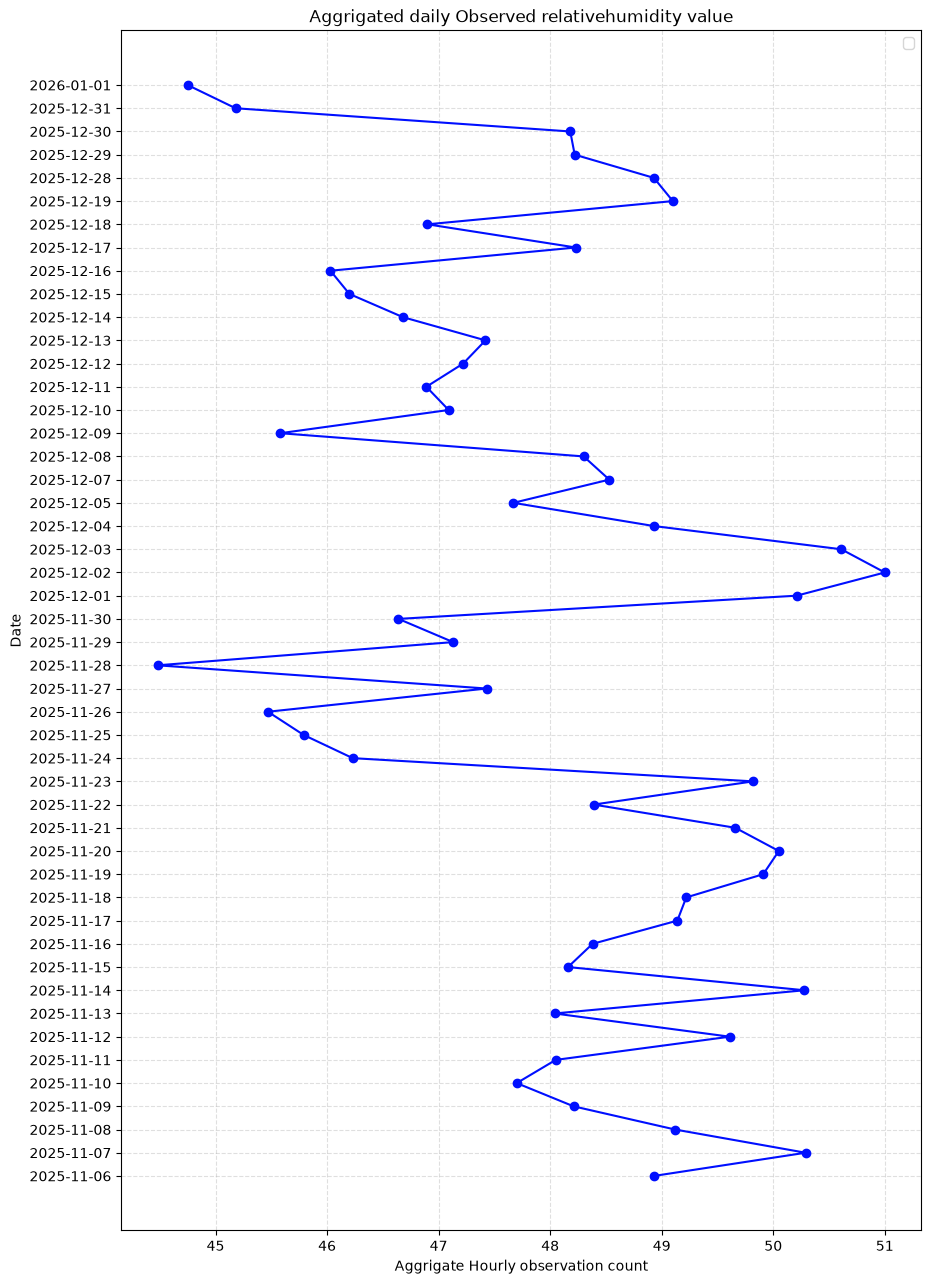

In [5]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and Visualization of last 30 days

In [6]:
df30 = pd.read_csv('cleaned_TokhaLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121046,Tokha (SC-31) - GD Labs,relativehumidity,56.0,%,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-09-12,06:45:00
1,6121046,Tokha (SC-31) - GD Labs,relativehumidity,54.0,%,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-09-12,07:45:00
2,6121046,Tokha (SC-31) - GD Labs,relativehumidity,53.0,%,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-09-12,08:45:00
3,6121046,Tokha (SC-31) - GD Labs,relativehumidity,51.0,%,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-09-12,09:45:00
4,6121046,Tokha (SC-31) - GD Labs,relativehumidity,49.0,%,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
697,6121046,Tokha (SC-31) - GD Labs,relativehumidity,54.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
698,6121046,Tokha (SC-31) - GD Labs,relativehumidity,54.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
699,6121046,Tokha (SC-31) - GD Labs,relativehumidity,54.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
700,6121046,Tokha (SC-31) - GD Labs,relativehumidity,54.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [7]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df30.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [8]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-09-12,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,51.94,16
1,2026-09-13,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,51.38,24
2,2026-09-14,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,49.46,24
3,2026-09-15,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,48.62,24
4,2026-09-16,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,48.92,24
5,2026-09-17,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,48.17,24
6,2026-09-18,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,50.88,24
7,2026-09-19,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,52.57,21
8,2026-09-20,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,50.25,24
9,2026-09-21,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,49.38,24


/tmp/ipykernel_50208/1124759186.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


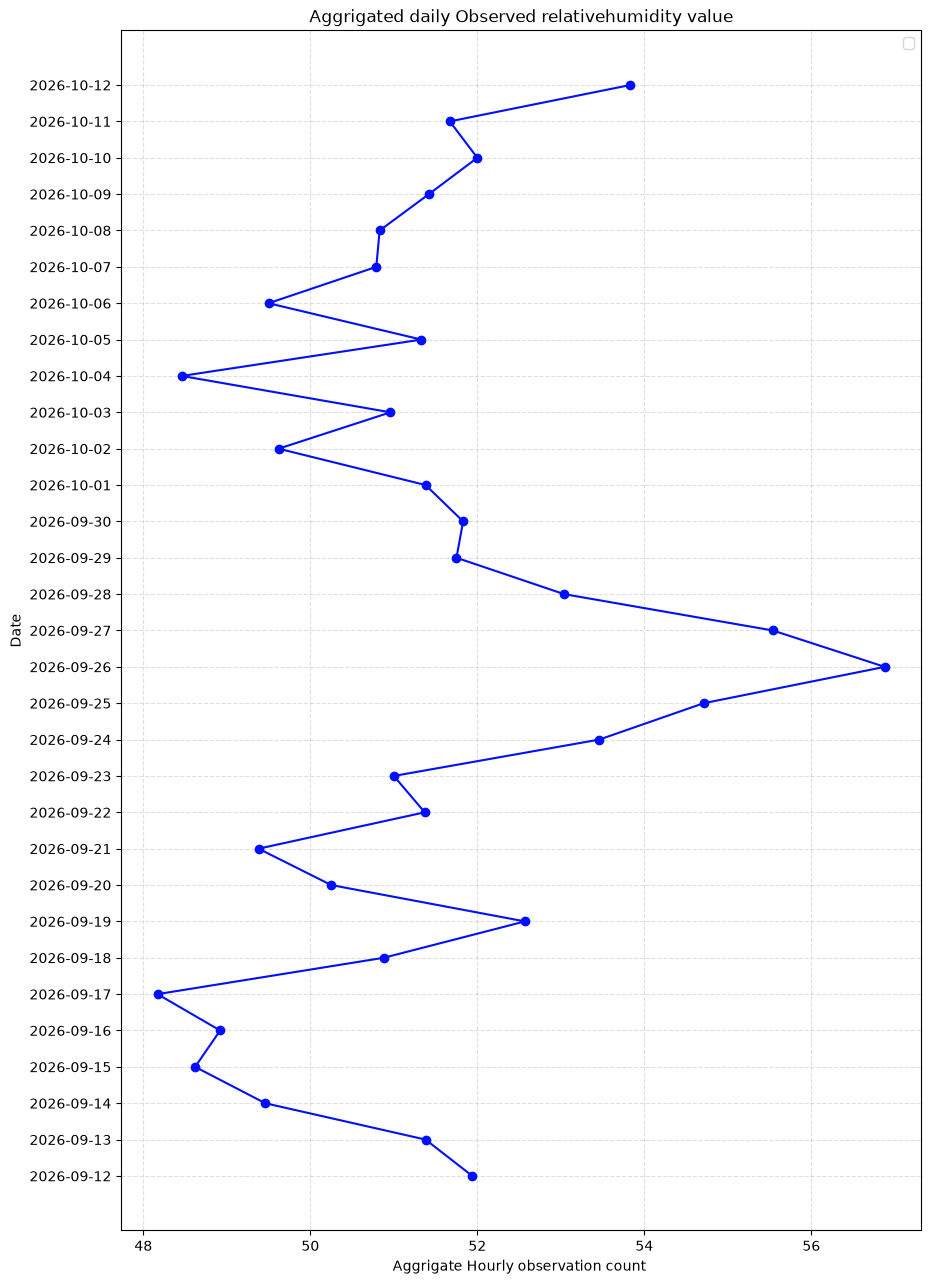

In [9]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 7 days

In [10]:
df7 = pd.read_csv('cleaned_TokhaLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121046,Tokha (SC-31) - GD Labs,relativehumidity,52.0,%,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,6121046,Tokha (SC-31) - GD Labs,relativehumidity,52.0,%,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,6121046,Tokha (SC-31) - GD Labs,relativehumidity,51.0,%,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,6121046,Tokha (SC-31) - GD Labs,relativehumidity,51.0,%,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,6121046,Tokha (SC-31) - GD Labs,relativehumidity,49.0,%,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,6121046,Tokha (SC-31) - GD Labs,relativehumidity,54.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
156,6121046,Tokha (SC-31) - GD Labs,relativehumidity,54.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
157,6121046,Tokha (SC-31) - GD Labs,relativehumidity,54.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
158,6121046,Tokha (SC-31) - GD Labs,relativehumidity,54.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [11]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df7.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [12]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-10-05,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,51.28,18
1,2026-10-06,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,49.50,16
2,2026-10-07,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,50.79,24
3,2026-10-08,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,50.83,24
4,2026-10-09,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,51.42,24
5,2026-10-10,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,52.00,24
6,2026-10-11,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,51.67,24
7,2026-10-12,6121046,Tokha (SC-31) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,53.83,6


/tmp/ipykernel_50208/3434928225.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


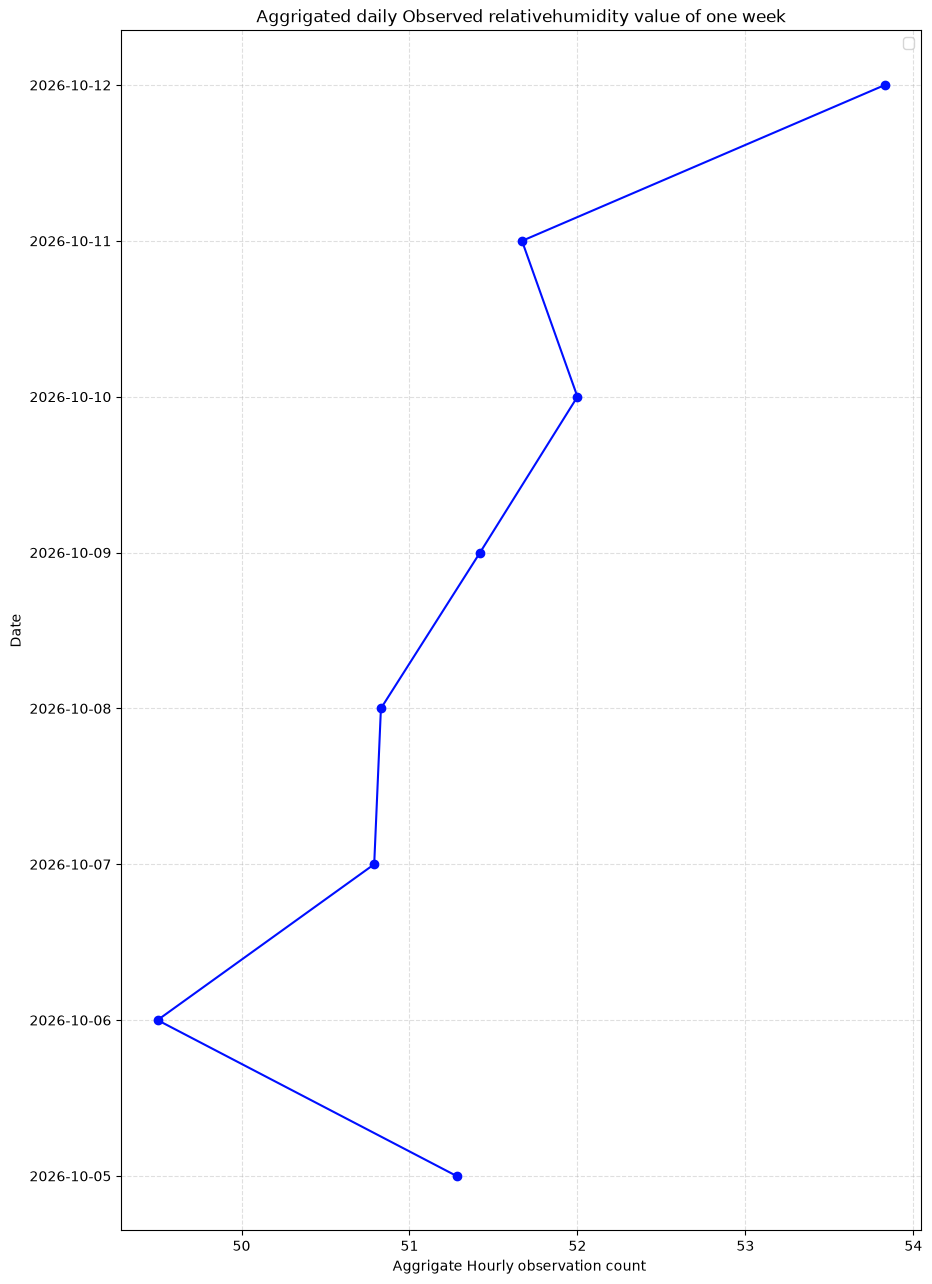

In [13]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [14]:
df24 = pd.read_csv('cleaned_TokhaLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6121046,Tokha (SC-31) - GD Labs,relativehumidity,56.0,%,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,6121046,Tokha (SC-31) - GD Labs,relativehumidity,56.0,%,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,6121046,Tokha (SC-31) - GD Labs,relativehumidity,54.0,%,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,6121046,Tokha (SC-31) - GD Labs,relativehumidity,53.0,%,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,6121046,Tokha (SC-31) - GD Labs,relativehumidity,51.0,%,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,6121046,Tokha (SC-31) - GD Labs,relativehumidity,47.0,%,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,6121046,Tokha (SC-31) - GD Labs,relativehumidity,47.0,%,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,6121046,Tokha (SC-31) - GD Labs,relativehumidity,46.0,%,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,6121046,Tokha (SC-31) - GD Labs,relativehumidity,46.0,%,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,6121046,Tokha (SC-31) - GD Labs,relativehumidity,47.0,%,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.756028,85.326846,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


/tmp/ipykernel_50208/1036584907.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


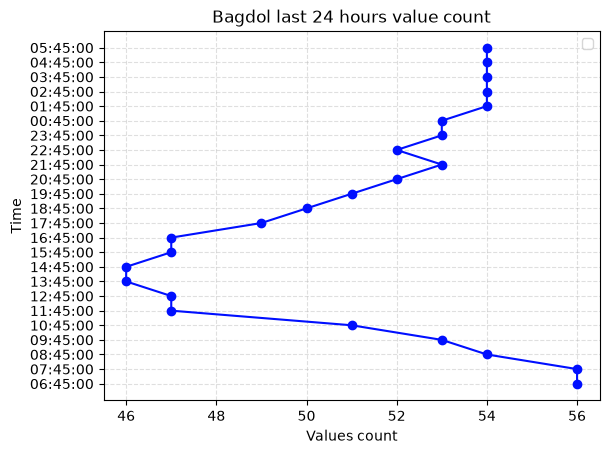

In [15]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Bagdol last 24 hours value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()